# 02 — What does upsampling leave behind? Simulation on Gaussian noise

**Goal:** understand the traces that an upsampling operation leaves in an image, in a
setting where we know the ground truth. We start from white Gaussian noise (no content,
no structure: every pixel independent), upsample it with different interpolation
kernels, and look at the result with the same tools as notebook 01 (high-pass +
autocorrelation), plus the power spectrum.

If Firefly's periodic signal comes from an upsampling step, one of these kernels should
reproduce the signatures seen in notebook 01 (period-2 zigzag in the autocorrelation,
bumps every 8 px, ...), or at least tell us which signatures upsampling *cannot* explain.

**Why simulate?** On real images we can't tell which part of a trace comes from the
generator and which from the content. Here we control everything: the input is pure
random noise with no structure, so *any* structure in the output was created by the
upsampling.

**What "upsampling" means.** Making an image larger (here ×2: 512×512 → 1024×1024).
The new pixels have to be invented from their neighbours; the rule used to compute them
is the **kernel** (how much each neighbouring input pixel contributes).

**Steps of this notebook**
1. Implement the upsampling methods ourselves (and check them against PIL).
2. Look at upsampled noise up close.
3. Power spectrum: which frequencies each method lets through.
4. Autocorrelation of the upsampled noise.
5. The same pipeline as notebook 01, compared with the Firefly result.
6. Does a pixel's position (even/odd) change its statistics?
7. Transposed convolution, the "learned" upsampling used in neural networks.

Kernels studied (all separable, i.e. applied along rows then columns):

| name | kernel | used by |
|---|---|---|
| nearest | box | nearest-neighbour / `ConvTranspose` with constant kernel |
| bilinear | triangle | most frameworks |
| bicubic a=-0.5 | Keys cubic | PIL, MATLAB |
| bicubic a=-0.75 | Keys cubic | OpenCV, PyTorch `interpolate` |
| lanczos2 / lanczos3 | windowed sinc | PIL (`LANCZOS` = lanczos3), image editors |

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
from PIL import Image
from scipy.ndimage import gaussian_filter


# Project folders. The notebook may be started from the project root or from notebooks/,
# so we walk up until we find the folder containing pyproject.toml.
PROJECT_ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "pyproject.toml").exists())
RESULTS_DIR = PROJECT_ROOT / "results"

rng = np.random.default_rng(0)

## 1. Upsampling, implemented explicitly

We implement interpolation ourselves rather than calling a library, so every choice is
visible. Conventions:

- **Pixel-center alignment** (`align_corners=False`, the default in PIL/OpenCV/PyTorch):
  output pixel $i$ samples the input at $x = (i + 0.5)/s - 0.5$ for factor $s$.
- **Periodic boundary** (wrap-around), so that borders introduce no artifacts and
  circular autocorrelation / FFT are exact.
- Weights are normalized to sum to 1 at every output pixel.

Each 1D resampling is a matrix $W$ (n_out × n_in), and the 2D upsampling is
$Y = W_y X W_x^T$.

In [2]:
def k_nearest(t):
    return ((t >= -0.5) & (t < 0.5)).astype(float)


def k_linear(t):
    return np.clip(1 - np.abs(t), 0, None)


def k_cubic(a):
    def k(t):
        t = np.abs(t)
        return np.where(
            t <= 1,
            (a + 2) * t**3 - (a + 3) * t**2 + 1,
            np.where(t < 2, a * t**3 - 5 * a * t**2 + 8 * a * t - 4 * a, 0.0),
        )
    return k


def k_lanczos(n):
    def k(t):
        return np.where(np.abs(t) < n, np.sinc(t) * np.sinc(t / n), 0.0)
    return k


KERNELS = {  # name -> (kernel, support radius in input pixels)
    "nearest": (k_nearest, 1),
    "bilinear": (k_linear, 1),
    "bicubic a=-0.5": (k_cubic(-0.5), 2),
    "bicubic a=-0.75": (k_cubic(-0.75), 2),
    "lanczos2": (k_lanczos(2), 2),
    "lanczos3": (k_lanczos(3), 3),
}


def resample_matrix(n_in, factor, kernel, support):
    """(n_out, n_in) interpolation matrix, pixel-center aligned, periodic boundary."""
    n_out = int(round(n_in * factor))
    x = (np.arange(n_out) + 0.5) / factor - 0.5          # source coordinate of each output pixel
    j = np.floor(x)[:, None] + np.arange(-support + 1, support + 1)  # neighbouring input pixels
    w = kernel(x[:, None] - j)
    w /= w.sum(axis=1, keepdims=True)
    W = np.zeros((n_out, n_in))
    np.add.at(W, (np.repeat(np.arange(n_out), j.shape[1]), j.astype(int).ravel() % n_in), w.ravel())
    return W


def upsample(x, factor, method):
    kernel, support = KERNELS[method]
    Wy = resample_matrix(x.shape[0], factor, kernel, support)
    Wx = resample_matrix(x.shape[1], factor, kernel, support)
    return Wy @ x @ Wx.T

### Sanity check against PIL

PIL's `resize` uses the same pixel-center convention, with `BICUBIC` = Keys a=-0.5 and
`LANCZOS` = lanczos3. Away from the borders (where PIL clamps instead of wrapping) the
two implementations should agree to floating-point precision.

In [3]:
x = rng.standard_normal((64, 64)).astype(np.float32)
pil_filters = {"nearest": Image.NEAREST, "bilinear": Image.BILINEAR,
               "bicubic a=-0.5": Image.BICUBIC, "lanczos3": Image.LANCZOS}
for name, f in pil_filters.items():
    ref = np.asarray(Image.fromarray(x, mode="F").resize((128, 128), f), dtype=np.float64)
    ours = upsample(x.astype(np.float64), 2, name)
    inner = (slice(8, -8), slice(8, -8))
    print(f"{name:16s} max |ours - PIL| (interior) = {np.abs(ours - ref)[inner].max():.2e}")

nearest          max |ours - PIL| (interior) = 0.00e+00
bilinear         max |ours - PIL| (interior) = 1.58e-07
bicubic a=-0.5   max |ours - PIL| (interior) = 2.02e-07
lanczos3         max |ours - PIL| (interior) = 2.11e-07


**What we see.** Our implementation gives the same numbers as PIL (differences of about
1e-7, i.e. float32 rounding). So our upsampling is the standard one, and we can trust
the rest of the notebook.

## 2. Upsampled noise, up close

Low-resolution white noise (512×512, σ = 1) upsampled ×2 to 1024×1024. Each panel shows
the same 32×32 corner, so the interpolation structure is visible pixel by pixel.

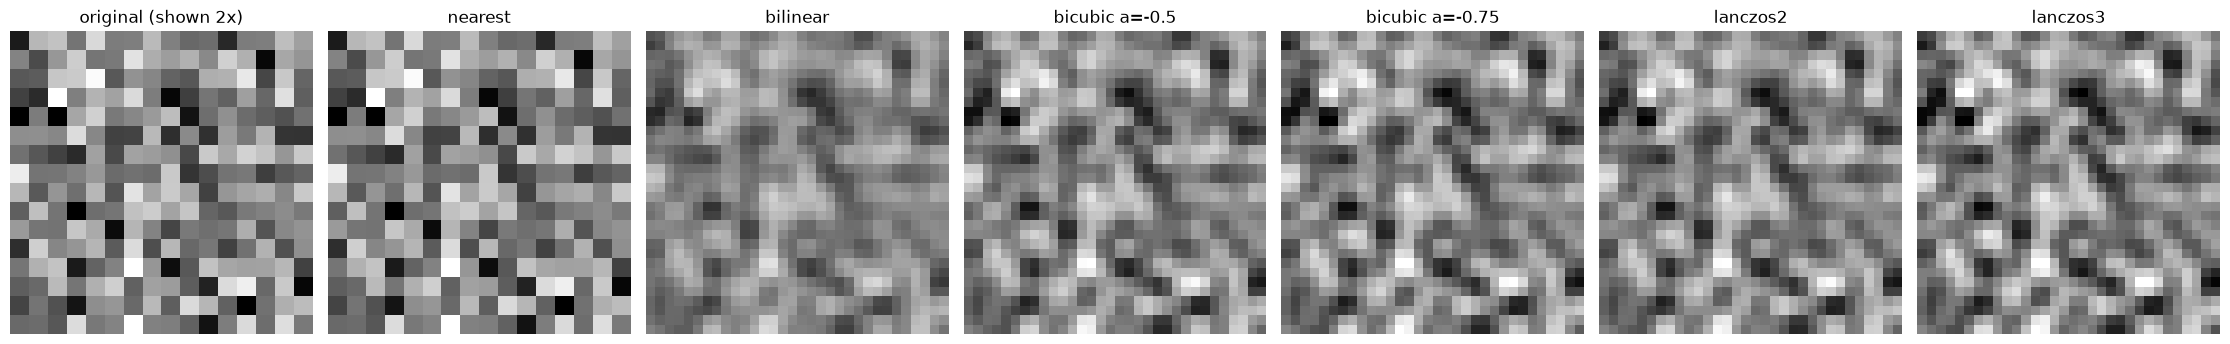

In [4]:
N_LOW, FACTOR = 512, 2
noise = rng.standard_normal((N_LOW, N_LOW))
up = {m: upsample(noise, FACTOR, m) for m in KERNELS}

fig, axes = plt.subplots(1, len(up) + 1, figsize=(3.2 * (len(up) + 1), 3.4))
axes[0].imshow(np.kron(noise[:16, :16], np.ones((2, 2))), cmap="gray", vmin=-2.5, vmax=2.5)
axes[0].set_title("original (shown 2x)")
for ax, (m, y) in zip(axes[1:], up.items()):
    ax.imshow(y[:32, :32], cmap="gray", vmin=-2.5, vmax=2.5)
    ax.set_title(m)
for ax in axes:
    ax.axis("off")
fig.tight_layout()

**What we see.** Left: the original noise, each pixel drawn as a 2×2 block. Then the same
area after each method.
- **nearest** copies each pixel into a 2×2 block, so it looks blocky.
- **bilinear** averages neighbours, so it is the blurriest.
- **bicubic** and **Lanczos** are sharper: their kernels have small negative lobes that
  keep edges crisper.

## 3. Power spectrum

White noise has a flat spectrum up to the low-resolution Nyquist frequency, 0.5 cycles
per *low-res* pixel = **0.25 cycles per output pixel**. Upsampling ×2 creates a spectral
**replica** of this band in [0.25, 0.5]; the interpolation kernel is a low-pass filter
that attenuates the replica, more or less well. What survives above 0.25 is the
upsampling fingerprint. The theoretical curve is $|\hat k(f)|^2$, the kernel's frequency
response.

Averaged over 16 noise realizations for a smooth estimate.

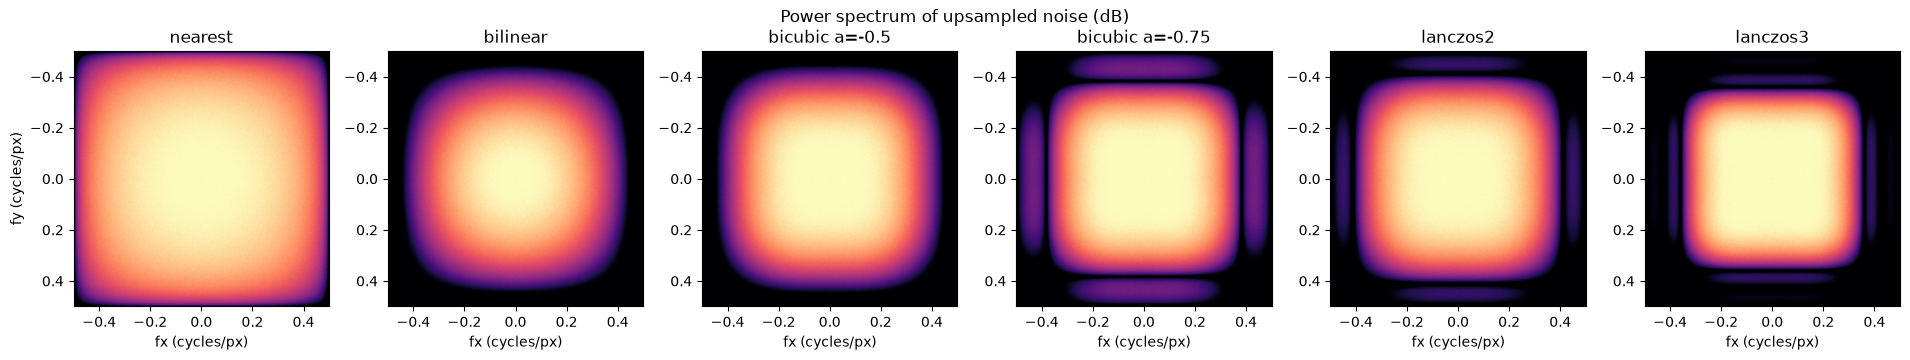

In [5]:
def power_spectrum(x):
    return np.fft.fftshift(np.abs(np.fft.fft2(x - x.mean())) ** 2) / x.size


N_REAL = 16
psd = {m: 0 for m in KERNELS}
for _ in range(N_REAL):
    z = rng.standard_normal((N_LOW, N_LOW))
    for m in KERNELS:
        psd[m] = psd[m] + power_spectrum(upsample(z, FACTOR, m)) / N_REAL

n = N_LOW * FACTOR
freqs = np.fft.fftshift(np.fft.fftfreq(n))

fig, axes = plt.subplots(1, len(psd), figsize=(3.2 * len(psd), 3.4))
for ax, (m, p) in zip(axes, psd.items()):
    ax.imshow(10 * np.log10(p + 1e-12), cmap="magma", vmin=-40, vmax=5,
              extent=(-0.5, 0.5, 0.5, -0.5))
    ax.set_title(m)
    ax.set_xlabel("fx (cycles/px)")
axes[0].set_ylabel("fy (cycles/px)")
fig.suptitle("Power spectrum of upsampled noise (dB)")
fig.tight_layout()

**How to read this.** The power spectrum shows how much of each spatial frequency
(fine vs coarse detail) the image contains: center = coarse, edges = finest detail
(alternating every pixel). Bright = a lot, dark = little.

**What we see.** The original noise only contains frequencies up to 0.25 cycles/px
(the central square); upsampling ×2 can't create genuinely finer detail. Each method
leaves a different amount of energy *outside* that square:
- nearest leaks a lot, out to the edges;
- bilinear and bicubic fade out progressively;
- lanczos3 cuts most sharply.

This "leak" is the fingerprint an upsampling method leaves in the frequencies.

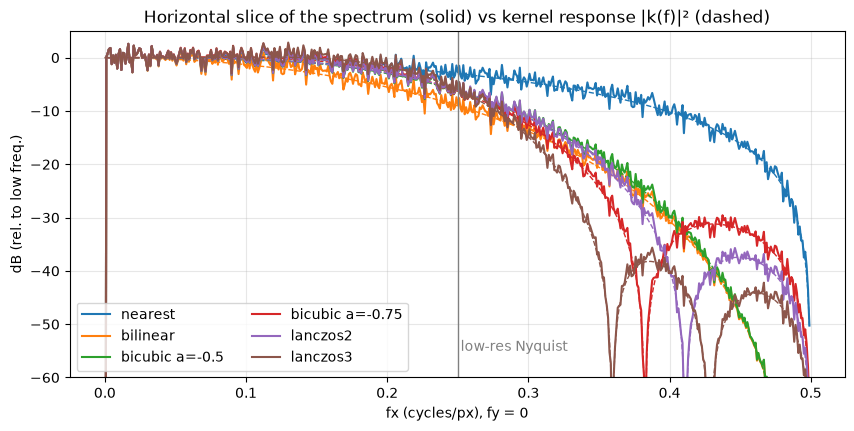

In [6]:
def kernel_response(kernel, support, factor, f):
    """|DTFT| of the equivalent filter on the output grid, normalized to 1 at f=0.

    Upsampling = zero-insertion followed by filtering with h[n] = k((n - (s-1)/2) / s):
    with pixel-center alignment the output pixels sit at offsets of (s-1)/2 output
    pixels from the input samples (±0.25 input px for s = 2).
    """
    t = (np.arange(-support * factor, support * factor + 1) - (factor - 1) / 2) / factor
    h = kernel(t)
    H = np.abs(np.exp(-2j * np.pi * np.outer(f, np.arange(len(h)))) @ h)
    return H / H[np.argmin(np.abs(f))]


pos = freqs >= 0
fig, ax = plt.subplots(figsize=(10, 4.5))
for m, p in psd.items():
    line, = ax.plot(freqs[pos], 10 * np.log10(p[n // 2, pos] / p[n // 2, n // 2 + 1]), lw=1.5, label=m)
    kernel, support = KERNELS[m]
    resp = kernel_response(kernel, support, FACTOR, freqs[pos])
    ax.plot(freqs[pos], 20 * np.log10(resp + 1e-12), lw=1, ls="--", color=line.get_color())
ax.axvline(0.25, color="gray", lw=1)
ax.text(0.252, -55, "low-res Nyquist", color="gray")
ax.set(xlabel="fx (cycles/px), fy = 0", ylabel="dB (rel. to low freq.)", ylim=(-60, 5),
       title="Horizontal slice of the spectrum (solid) vs kernel response |k(f)|² (dashed)")
ax.grid(alpha=0.3)
ax.legend(ncol=2)

**What we see.** A cut through the spectra along the horizontal axis (solid), with the
theoretical response of each kernel (dashed). They match, which confirms we understand
what each kernel does. Beyond the low-res Nyquist line (0.25), the curves show how much
of the fake high frequencies each method leaves: from about −5 dB (nearest) down to
below −40 dB (lanczos3), with a visible bump for bicubic a=−0.75 near 0.43.

## 4. Autocorrelation

Normalized circular autocorrelation (as in notebook 01), first of the raw upsampled
noise: it is the inverse Fourier transform of the spectrum above, so it shows the
*correlation introduced between neighbouring pixels* by the interpolation.

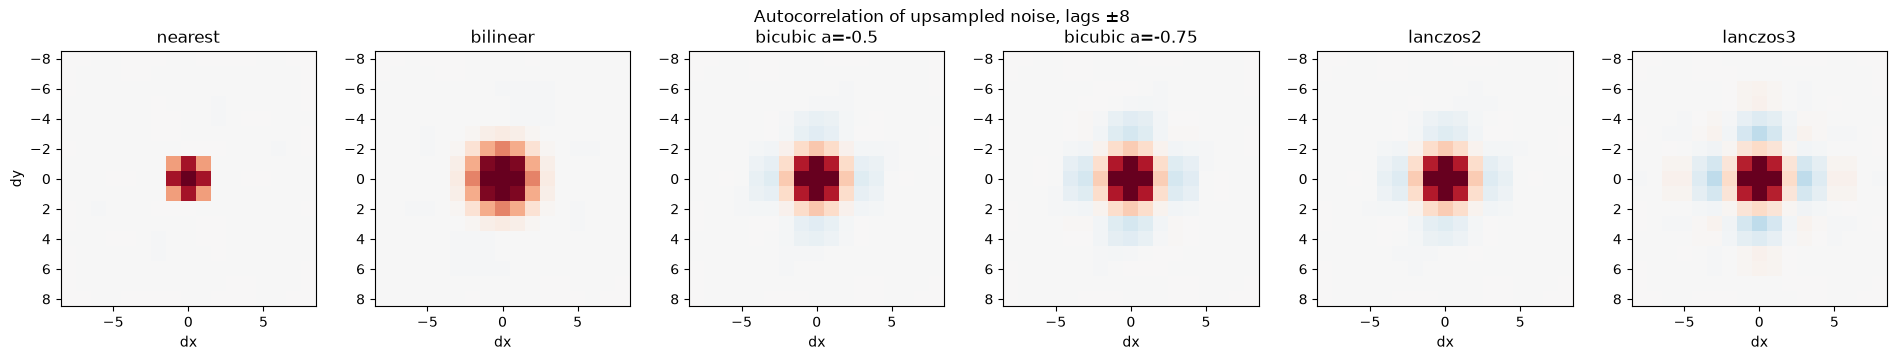

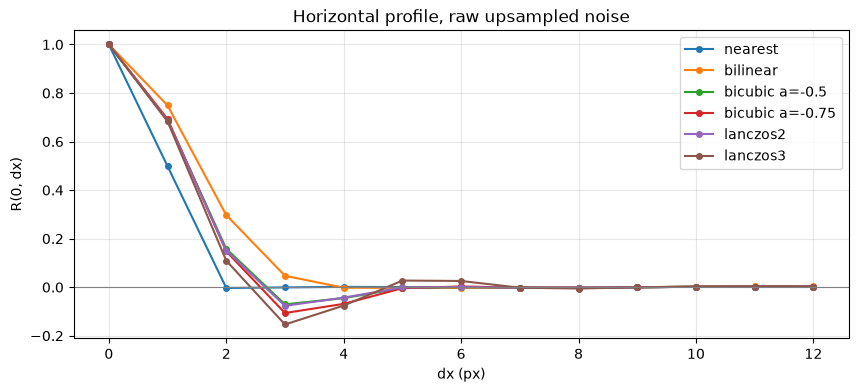

In [7]:
LAG = 32


def autocorrelation(x):
    x = x - x.mean()
    r = np.fft.ifft2(np.abs(np.fft.fft2(x)) ** 2).real
    return np.fft.fftshift(r / r.flat[0])


def crop_center(x, half):
    cy, cx = x.shape[0] // 2, x.shape[1] // 2
    return x[cy - half : cy + half + 1, cx - half : cx + half + 1]


acf = {m: crop_center(autocorrelation(y), LAG) for m, y in up.items()}
lags = np.arange(-LAG, LAG + 1)

fig, axes = plt.subplots(1, len(acf), figsize=(3.2 * len(acf), 3.4))
for ax, (m, r) in zip(axes, acf.items()):
    v = 0.6
    ax.imshow(crop_center(r, 8), cmap="RdBu_r", vmin=-v, vmax=v, extent=(-8.5, 8.5, 8.5, -8.5))
    ax.set_title(m)
    ax.set_xlabel("dx")
axes[0].set_ylabel("dy")
fig.suptitle("Autocorrelation of upsampled noise, lags ±8")
fig.tight_layout()

fig, ax = plt.subplots(figsize=(10, 4))
for m, r in acf.items():
    ax.plot(lags[LAG:LAG + 13], r[LAG, LAG:LAG + 13], marker="o", ms=4, lw=1.5, label=m)
ax.axhline(0, color="gray", lw=0.8)
ax.set(xlabel="dx (px)", ylabel="R(0, dx)", title="Horizontal profile, raw upsampled noise")
ax.grid(alpha=0.3)
ax.legend()

**What we see.** Before upsampling, noise pixels are unrelated: R = 0 for any shift.
After upsampling, neighbours become correlated, because new pixels are computed from the
same inputs. But the correlation is **short-range**: it is gone after 3–6 pixels for
every method. Lanczos and bicubic even go slightly negative around 2–3 px (their
negative lobes).

## 5. Same pipeline as notebook 01: high-pass, then autocorrelation

Notebook 01 high-passed the Firefly mean images with `x - gaussian_blur(x, σ=2)` before
the autocorrelation. Applying the exact same steps here lets us compare the profiles
directly with Firefly's (loaded from notebook 01's cached means; run it first).

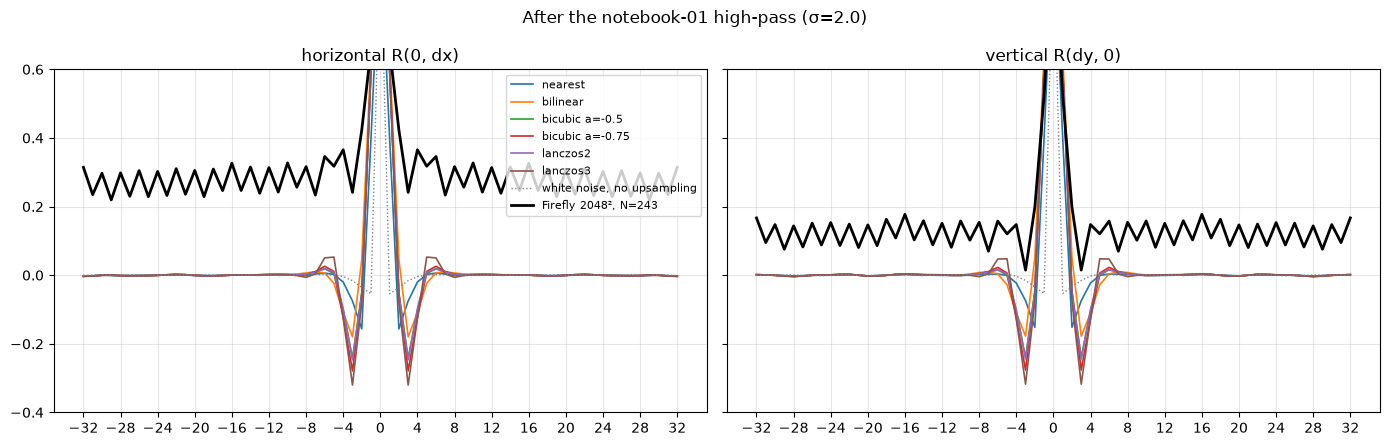

In [8]:
SIGMA = 2.0


def highpass(x, sigma=SIGMA):
    return x - gaussian_filter(x, sigma, mode="wrap")


acf_hp = {m: crop_center(autocorrelation(highpass(y)), LAG) for m, y in up.items()}

ff_file = RESULTS_DIR / "01_mean_autocorr" / "mean_2048x2048_n243.npy"
acf_ff = crop_center(autocorrelation(highpass(np.load(ff_file))), LAG) if ff_file.exists() else None
acf_white = crop_center(autocorrelation(highpass(rng.standard_normal((1024, 1024)))), LAG)

fig, axes = plt.subplots(1, 2, figsize=(14, 4.5), sharey=True)
for ax, (title, prof) in zip(axes, [("horizontal R(0, dx)", lambda r: r[LAG, :]),
                                    ("vertical R(dy, 0)", lambda r: r[:, LAG])]):
    for m, r in acf_hp.items():
        ax.plot(lags, prof(r), lw=1.2, label=m)
    ax.plot(lags, prof(acf_white), lw=1, color="gray", ls=":", label="white noise, no upsampling")
    if acf_ff is not None:
        ax.plot(lags, prof(acf_ff), lw=2, color="black", label="Firefly 2048², N=243")
    ax.set_title(title)
    ax.set_xticks(np.arange(-LAG, LAG + 1, 4))
    ax.set_ylim(-0.4, 0.6)
    ax.grid(alpha=0.3)
axes[0].legend(fontsize=8)
fig.suptitle(f"After the notebook-01 high-pass (σ={SIGMA})")
fig.tight_layout()

**What we see.** The colored curves (simulated upsampling) go back to 0 within about
8 px. The black curve (Firefly, from notebook 01) stays around 0.2–0.3 at every shift
and zigzags with period 2 all the way.

**Conclusion:** upsampling *random content* with these interpolation methods does not
produce Firefly's signature. This makes sense: each image has its own content, so
nothing is shared between images, and nothing survives averaging. Firefly's signal must
be the *same* in every image.

## 6. Periodic statistics: does the pixel's position modulo 2 matter?

Interpolation treats output pixels differently depending on where they fall relative to
the input grid: with ×2 pixel-center alignment, even and odd output pixels sit at
input offsets −0.25 and +0.25. If the kernel is not symmetric between these two
positions, or if a pixel coincides with an input sample, statistics like the variance
become **periodic with the upsampling factor** (cyclostationarity). This is the kind of
signal a detector can exploit even when the pattern changes from image to image.

We compute the variance of the high-passed upsampled image for each phase
$(y \bmod 2, x \bmod 2)$.

In [9]:
def phase_variance(x, period=2):
    return np.array([[x[i::period, j::period].var() for j in range(period)] for i in range(period)])


for m, y in up.items():
    v = phase_variance(highpass(y))
    print(f"{m:16s} variance by phase (rows: y mod 2, cols: x mod 2):  "
          f"{v[0,0]:.4f} {v[0,1]:.4f} | {v[1,0]:.4f} {v[1,1]:.4f}   ratio max/min = {v.max()/v.min():.3f}")

nearest          variance by phase (rows: y mod 2, cols: x mod 2):  0.7952 0.7953 | 0.7953 0.7952   ratio max/min = 1.000
bilinear         variance by phase (rows: y mod 2, cols: x mod 2):  0.2282 0.2282 | 0.2282 0.2282   ratio max/min = 1.000
bicubic a=-0.5   variance by phase (rows: y mod 2, cols: x mod 2):  0.4435 0.4435 | 0.4435 0.4435   ratio max/min = 1.000
bicubic a=-0.75  variance by phase (rows: y mod 2, cols: x mod 2):  0.4985 0.4985 | 0.4985 0.4985   ratio max/min = 1.000
lanczos2         variance by phase (rows: y mod 2, cols: x mod 2):  0.4541 0.4541 | 0.4541 0.4541   ratio max/min = 1.000
lanczos3         variance by phase (rows: y mod 2, cols: x mod 2):  0.5651 0.5651 | 0.5651 0.5651   ratio max/min = 1.000


**What we see.** The four numbers per line are the variance of the pixels at even/odd
rows × even/odd columns. They are identical (ratio 1.000): with the standard
"pixel-center" alignment, every output pixel is computed in an equivalent way, so the
position mod 2 leaves no trace in the statistics.

With pixel-center alignment and a symmetric kernel the two phases are mirror images, so
the variances match. An **align-corners** convention (output pixel $i$ at
$x = i \cdot (n_{in}-1)/(n_{out}-1)$, or simply $x = i/s$) makes even output pixels
fall *exactly* on input samples: they are copies, while odd pixels are averages, with
lower variance. Let's check with $x = i/2$:

bilinear         variance by phase:  0.7910 0.3180 | 0.3199 0.0948   ratio max/min = 8.347
bicubic a=-0.5   variance by phase:  0.7764 0.4270 | 0.4291 0.2092   ratio max/min = 3.711
bicubic a=-0.75  variance by phase:  0.7691 0.4916 | 0.4939 0.2942   ratio max/min = 2.614
lanczos2         variance by phase:  0.7764 0.4270 | 0.4291 0.2092   ratio max/min = 3.711
lanczos3         variance by phase:  0.7665 0.5511 | 0.5529 0.3840   ratio max/min = 1.996


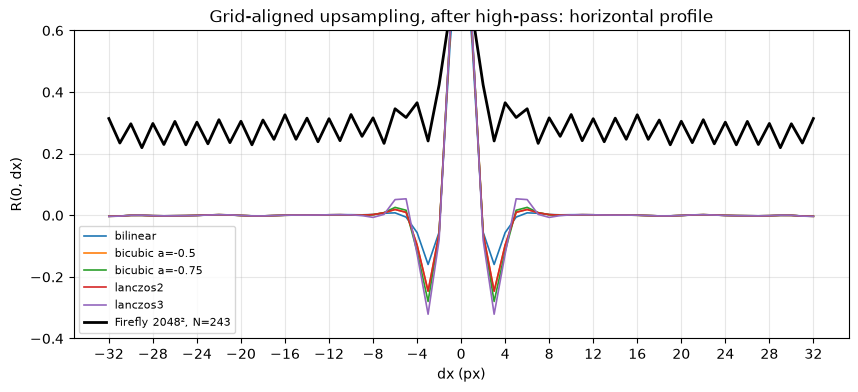

In [10]:
def upsample_on_grid(x, factor, method):
    """Like upsample(), but output pixel i samples the input at x = i / factor."""
    kernel, support = KERNELS[method]

    def mat(n_in):
        n_out = n_in * factor
        xs = np.arange(n_out) / factor
        j = np.floor(xs)[:, None] + np.arange(-support + 1, support + 1)
        w = kernel(xs[:, None] - j)
        w /= w.sum(axis=1, keepdims=True)
        W = np.zeros((n_out, n_in))
        np.add.at(W, (np.repeat(np.arange(n_out), j.shape[1]), j.astype(int).ravel() % n_in), w.ravel())
        return W

    return mat(x.shape[0]) @ x @ mat(x.shape[1]).T


up_grid = {m: upsample_on_grid(noise, FACTOR, m) for m in KERNELS if m != "nearest"}
for m, y in up_grid.items():
    v = phase_variance(highpass(y))
    print(f"{m:16s} variance by phase:  {v[0,0]:.4f} {v[0,1]:.4f} | {v[1,0]:.4f} {v[1,1]:.4f}"
          f"   ratio max/min = {v.max()/v.min():.3f}")

acf_grid = {m: crop_center(autocorrelation(highpass(y)), LAG) for m, y in up_grid.items()}
fig, ax = plt.subplots(figsize=(10, 4))
for m, r in acf_grid.items():
    ax.plot(lags, r[LAG, :], lw=1.2, label=m)
if acf_ff is not None:
    ax.plot(lags, acf_ff[LAG, :], lw=2, color="black", label="Firefly 2048², N=243")
ax.set(xlabel="dx (px)", ylabel="R(0, dx)", ylim=(-0.4, 0.6),
       title="Grid-aligned upsampling, after high-pass: horizontal profile")
ax.set_xticks(np.arange(-LAG, LAG + 1, 4))
ax.grid(alpha=0.3)
ax.legend(fontsize=8)

**What we see.** With grid alignment, the variance now depends strongly on the position
mod 2 (ratio max/min from 2.0 for lanczos3 up to 8.3 for bilinear):
- pixels at (even, even) are exact copies of input pixels, so they have the full
  variance;
- pixels between two input pixels are averages, so they have less variance.

This "periodic variance" is a real upsampling trace. But the autocorrelation curves
still don't look like Firefly's. A mean and an autocorrelation can't see it, because the
pattern is in the *variance* (how much pixels fluctuate), not in their average value.
To look for it in Firefly we would average the *squared* high-passed images instead.

(Side note: lanczos2 and bicubic a=−0.5 give exactly the same numbers here. On this grid
both kernels reduce to the same weights, 0.5625 and −0.0625.)

## 7. Transposed convolution

A transposed convolution with stride $s$ is **zero insertion followed by a convolution**:
put $s-1$ zeros between input pixels, then convolve with a kernel $K$. This is the
upsampling layer of many generators and decoders, with $K$ *learned*.

Interpolation is the special case where $K$ is a fixed, well-balanced kernel (for
bilinear ×2: the outer product of $[1/4, 3/4, 3/4, 1/4]$). Looking at it as zero insertion
explains what can go wrong: for stride 2, an output pixel at phase $(p, q) = (y \bmod 2, x \bmod 2)$
only receives the kernel taps $K[p::2,\, q::2]$, its **polyphase component**. If the four
components don't have the same sum, a constant input already gives a periodic output:
this is the **checkerboard artifact** (Odena et al., *Deconvolution and Checkerboard
Artifacts*, Distill 2016). Unlike the interpolation traces above, this pattern is
deterministic, the same in every image, so it survives averaging over images, as in
notebook 01.

Kernels compared (all scaled so the average gain is 1):

- **bilinear 4×4:** the interpolation kernel written as a transposed conv (balanced);
- **box 3×3:** uniform weights, but 3 is not divisible by the stride: uneven overlap;
- **random 3×3 / random 4×4:** random positive-mean weights, a stand-in for a learned kernel.

In [11]:
def transposed_conv(x, kernel, stride=2):
    """Zero insertion + convolution with `kernel`, periodic boundary."""
    u = np.zeros((x.shape[0] * stride, x.shape[1] * stride))
    u[::stride, ::stride] = x
    k = np.zeros_like(u)
    k[: kernel.shape[0], : kernel.shape[1]] = kernel
    return np.fft.ifft2(np.fft.fft2(u) * np.fft.fft2(k)).real


def normalize_gain(kernel, stride=2):
    return kernel * stride**2 / kernel.sum()


h_bilinear = k_linear((np.arange(-1, 3) - 0.5) / 2)  # [1/4, 3/4, 3/4, 1/4]
krng = np.random.default_rng(42)
TCONV_KERNELS = {
    "bilinear 4x4": np.outer(h_bilinear, h_bilinear),
    "box 3x3": normalize_gain(np.ones((3, 3))),
    "random 3x3": normalize_gain(krng.normal(1, 0.5, (3, 3))),
    "random 4x4": normalize_gain(krng.normal(1, 0.5, (4, 4))),
}

# Check: the bilinear transposed conv equals bilinear interpolation, up to a shift
# (the output alignment of a transposed conv is a matter of convention).
x = rng.standard_normal((64, 64))
y_tc, y_up = transposed_conv(x, TCONV_KERNELS["bilinear 4x4"]), upsample(x, 2, "bilinear")
err = min(np.abs(np.roll(y_tc, (-dy, -dx), (0, 1)) - y_up).max() for dy in range(4) for dx in range(4))
print(f"bilinear: max |transposed conv - interpolation| (best shift) = {err:.1e}")

bilinear: max |transposed conv - interpolation| (best shift) = 1.3e-15


**What we see.** The transposed convolution with the bilinear kernel gives exactly the
same image as bilinear interpolation, shifted by one pixel (difference ~1e-15). This
confirms that interpolation is a special case of transposed convolution.

### Constant input: the polyphase sums *are* the pattern

With a constant input $c$, the output at phase $(p, q)$ is $c \sum K[p::2, q::2]$.

bilinear 4x4  polyphase sums (rows: y mod 2): 1.000 1.000 | 1.000 1.000
box 3x3       polyphase sums (rows: y mod 2): 1.778 0.889 | 0.889 0.444
random 3x3    polyphase sums (rows: y mod 2): 2.366 0.682 | 0.939 0.013
random 4x4    polyphase sums (rows: y mod 2): 0.823 1.147 | 0.884 1.146


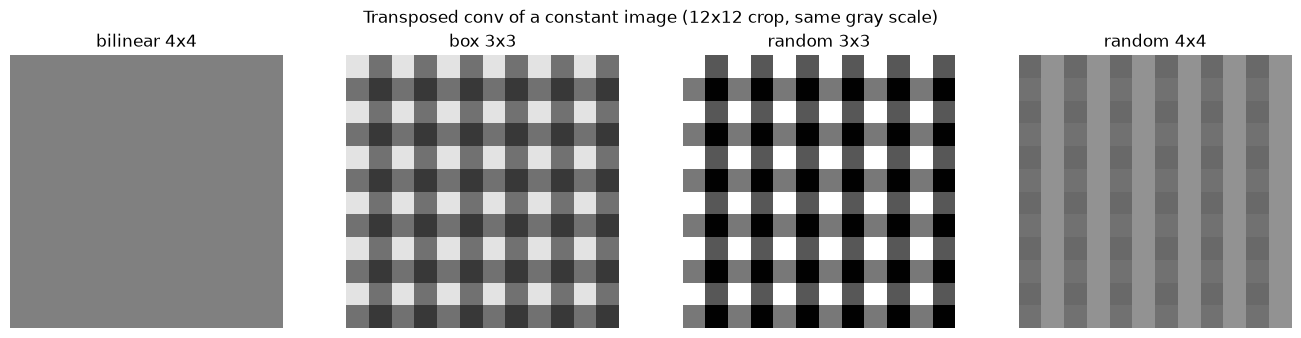

In [12]:
def polyphase_sums(kernel, stride=2):
    return np.array([[kernel[p::stride, q::stride].sum() for q in range(stride)]
                     for p in range(stride)])


fig, axes = plt.subplots(1, len(TCONV_KERNELS), figsize=(3.4 * len(TCONV_KERNELS), 3.4))
for ax, (name, K) in zip(axes, TCONV_KERNELS.items()):
    y = transposed_conv(np.ones((32, 32)), K)
    ax.imshow(y[:12, :12], cmap="gray", vmin=0, vmax=2)
    ax.set_title(name)
    ax.axis("off")
    s = polyphase_sums(K)
    print(f"{name:13s} polyphase sums (rows: y mod 2): {s[0,0]:.3f} {s[0,1]:.3f} | "
          f"{s[1,0]:.3f} {s[1,1]:.3f}")
fig.suptitle("Transposed conv of a constant image (12x12 crop, same gray scale)")
fig.tight_layout()

**What we see.** The input is a perfectly flat image. The output should be flat too, and
it is for bilinear. With the other kernels, the 4 positions (even/odd row × even/odd
column) get different total weights (the printed "polyphase sums"), so a flat image
comes out as a repeating pattern of period 2:
- **box 3×3** gives a checkerboard;
- **random 3×3** gives a strong checkerboard;
- **random 4×4** gives mostly vertical stripes. So even a kernel size that matches the
  stride is no guarantee: a learned kernel can still be unbalanced.

This pattern is **the same for every input image**, because it comes from the kernel,
not from the content. That is exactly the kind of signal notebook 01 found.

### Noise input: spectrum and periodic statistics

Zero-mean noise: the mean pattern vanishes, but each phase is still a different filter,
so the variance can depend on the phase. The spectrum shows how much of the replica
above 0.25 cycles/px survives (compare with the interpolation kernels in section 3).

bilinear 4x4  variance by phase: 0.2282 0.2282 | 0.2282 0.2282   ratio max/min = 1.000
box 3x3       variance by phase: 0.4695 0.2480 | 0.2465 0.1453   ratio max/min = 3.231
random 3x3    variance by phase: 0.9840 0.1560 | 0.4485 0.0620   ratio max/min = 15.876
random 4x4    variance by phase: 0.0954 0.1779 | 0.1222 0.1866   ratio max/min = 1.956


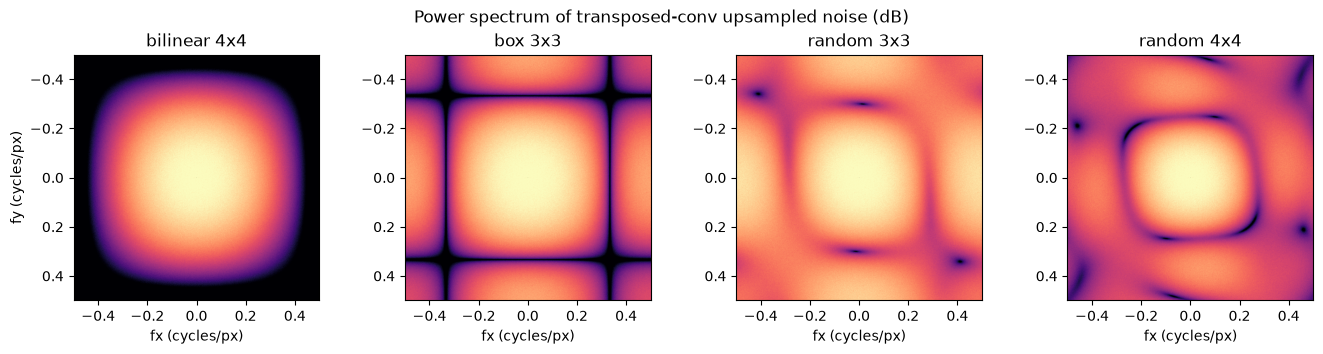

In [13]:
psd_tc = {name: 0 for name in TCONV_KERNELS}
for _ in range(N_REAL):
    z = rng.standard_normal((N_LOW, N_LOW))
    for name, K in TCONV_KERNELS.items():
        psd_tc[name] = psd_tc[name] + power_spectrum(transposed_conv(z, K)) / N_REAL

fig, axes = plt.subplots(1, len(psd_tc), figsize=(3.4 * len(psd_tc), 3.4))
for ax, (name, p) in zip(axes, psd_tc.items()):
    ax.imshow(10 * np.log10(p + 1e-12), cmap="magma", vmin=-40, vmax=5,
              extent=(-0.5, 0.5, 0.5, -0.5))
    ax.set_title(name)
    ax.set_xlabel("fx (cycles/px)")
axes[0].set_ylabel("fy (cycles/px)")
fig.suptitle("Power spectrum of transposed-conv upsampled noise (dB)")
fig.tight_layout()

for name, K in TCONV_KERNELS.items():
    v = phase_variance(highpass(transposed_conv(noise, K)))
    print(f"{name:13s} variance by phase: {v[0,0]:.4f} {v[0,1]:.4f} | {v[1,0]:.4f} {v[1,1]:.4f}"
          f"   ratio max/min = {v.max()/v.min():.3f}")

**What we see.**
- **Spectra:** bilinear looks like before. The unbalanced kernels let much more energy
  through at high frequencies, with notches (dark lines/spots) at kernel-specific
  places.
- **Variance by position:** for the unbalanced kernels the variance also depends on
  position mod 2 (ratios 3.2, 15.9, 2.0).

So they leave both kinds of trace: a fixed pattern, and a periodic variance.

### Mimicking notebook 01: average many upsampled images, then autocorrelate

Real images have a non-zero mean (content, or a bias in the network), so the
deterministic pattern of the constant-input case gets added to every image. We simulate
`N_IMG` images as noise with mean `MU`, upsample each with the same kernel, average them,
and run the notebook-01 pipeline (high-pass, autocorrelation). The Firefly profile is
overlaid for comparison.

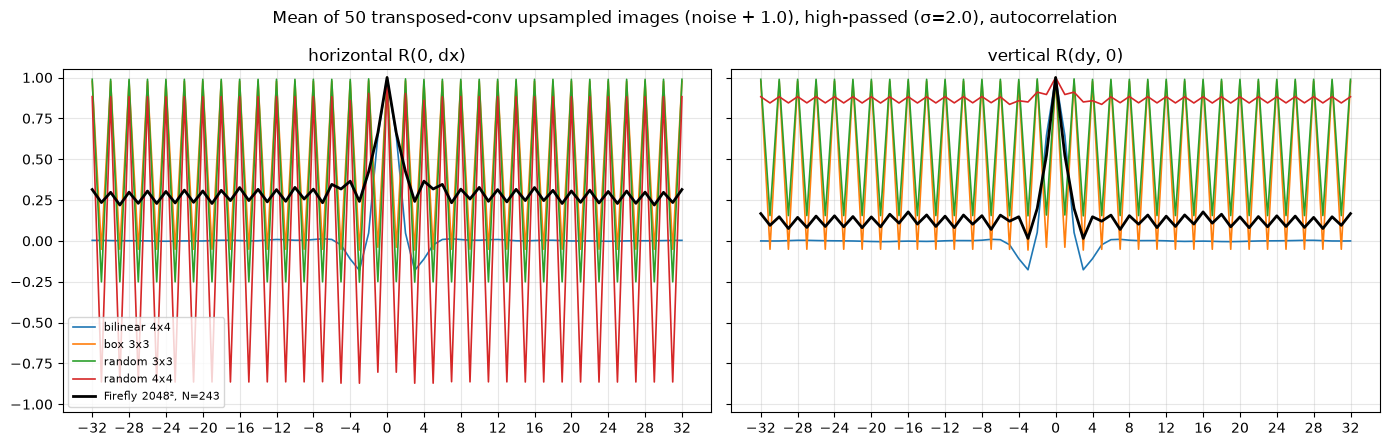

In [14]:
N_IMG, MU = 50, 1.0
mean_tc = {name: 0 for name in TCONV_KERNELS}
for _ in range(N_IMG):
    z = MU + rng.standard_normal((N_LOW, N_LOW))
    for name, K in TCONV_KERNELS.items():
        mean_tc[name] = mean_tc[name] + transposed_conv(z, K) / N_IMG

acf_tc = {name: crop_center(autocorrelation(highpass(m)), LAG) for name, m in mean_tc.items()}
fig, axes = plt.subplots(1, 2, figsize=(14, 4.5), sharey=True)
for ax, (title, prof) in zip(axes, [("horizontal R(0, dx)", lambda r: r[LAG, :]),
                                    ("vertical R(dy, 0)", lambda r: r[:, LAG])]):
    for name, r in acf_tc.items():
        ax.plot(lags, prof(r), lw=1.2, label=name)
    if acf_ff is not None:
        ax.plot(lags, prof(acf_ff), lw=2, color="black", label="Firefly 2048², N=243")
    ax.set_title(title)
    ax.set_xticks(np.arange(-LAG, LAG + 1, 4))
    ax.set_ylim(-1.05, 1.05)
    ax.grid(alpha=0.3)
axes[0].legend(fontsize=8)
fig.suptitle(f"Mean of {N_IMG} transposed-conv upsampled images (noise + {MU}), "
             f"high-passed (σ={SIGMA}), autocorrelation")
fig.tight_layout()

**What we see.** This repeats notebook 01's procedure on simulated images. The
unbalanced kernels produce a **period-2 zigzag that does not decay with distance**:
the same signature as Firefly (black), which none of the interpolation methods produced.
The random 4×4 kernel also gives a flat, high vertical profile, because its pattern is
stripes. That could explain the strong row/column lines in Firefly's autocorrelation.

The simulated zigzag is much stronger than Firefly's (about ±1 vs ±0.04). That's
expected, since we chose a strong pattern and the simulated images have no real
content. The *shape* matches; the *amplitude* would need fitting.

## Observations

1. **Interpolation (nearest, bilinear, bicubic, Lanczos) only creates short-range
   correlations** (a few pixels) and a frequency fingerprint above the low-res Nyquist
   frequency. It creates **no pattern shared between images**, so it can't explain the
   signal found by averaging Firefly images in notebook 01.
2. **The alignment convention matters.** With grid alignment, pixels that coincide with
   input pixels have more variance than interpolated ones: a period-2 trace in the
   *variance*, invisible to mean + autocorrelation.
3. **Transposed convolution with an unbalanced kernel** (as can happen with learned
   kernels) turns even a flat image into a fixed period-2 pattern: the checkerboard
   artifact. This pattern is the same in every image, survives averaging, and
   reproduces Firefly's non-decaying period-2 zigzag. Kernels producing stripes could
   also explain the strong row/column lines.

**Working hypothesis:** Firefly's signal comes from a learned upsampling layer
(transposed convolution or similar) whose kernel is not perfectly balanced between
the 4 positions of each 2×2 output block.

**Possible next steps**
- Estimate Firefly's pattern directly: average each of the 4 positions (even/odd row ×
  even/odd column) of the high-passed images, and compare them.
- Average the *squared* high-passed Firefly images, to look for a periodic variance.
- Look for the 8-px structure (cascaded ×2 upsamplings give ×8 overall).
- Test robustness: JPEG compression, resizing.